0. 제출 정보

- 이름: 예민호

- GitHub ID: yegamanse-cpu

- 작성일: 2026.10.27

- 최종 제출 URL: https://github.com/yegamanse-cpu/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
|월별 완료 주문 금액은 어떻게 변하는가?|선그래프|월은 시간 순서가 있으니까 흐름을 보려면 선그래프가 적합|
|상품 가격은 어느 구간에 몰려 있는가?|히스토그램|값이 어느 가격대에 몰려 있는지가 확인하기 위해 히스토그램 선택|
|상품 가격과 완료 주문 판매 수량은 어떤 패턴인가?|산점도|두 값이 어떤 관계가 있는 지 확인하기 위해 산점도 선택|


In [4]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
    
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)
     

현재 실행 위치: c:\dev\llm-data-analysis-course\notebooks\ch07
프로젝트 루트: c:\dev\llm-data-analysis-course
전처리 데이터 폴더: c:\dev\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\dev\llm-data-analysis-course\reports\figures


- 챕터06 과제와 같이 src모듈 불러오기 오류가 발생하여 가이드노트북의 코드를 수정 조치 

In [5]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 474
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 0


In [6]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,148990000.0,148990000.0,0.0,True
1,product_completed_amount,148990000.0,148990000.0,0.0,True
2,customer_completed_amount,148990000.0,148990000.0,0.0,True
3,monthly_completed_amount_valid_dates,148990000.0,148990000.0,0.0,True


- 총합 검증 결과: 모든 passed가 true로 확인
- 문제가 있었다면 원인: 처음 시도 시 src/visulation.py 파일 코드가 과거버젼(26.9월추정)으로 일부 키가 정의되지 않아 오류가 발생. 최신 코드로 수정하여 오류해결
- 시각화를 진행해도 된다고 판단한 이유:모든 값이 이상이 없으므로 시각화 진행

In [7]:

from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,11546000,16,721625.0
8,2026-05,16631000,19,875316.0
9,2026-06,12504000,17,735529.0


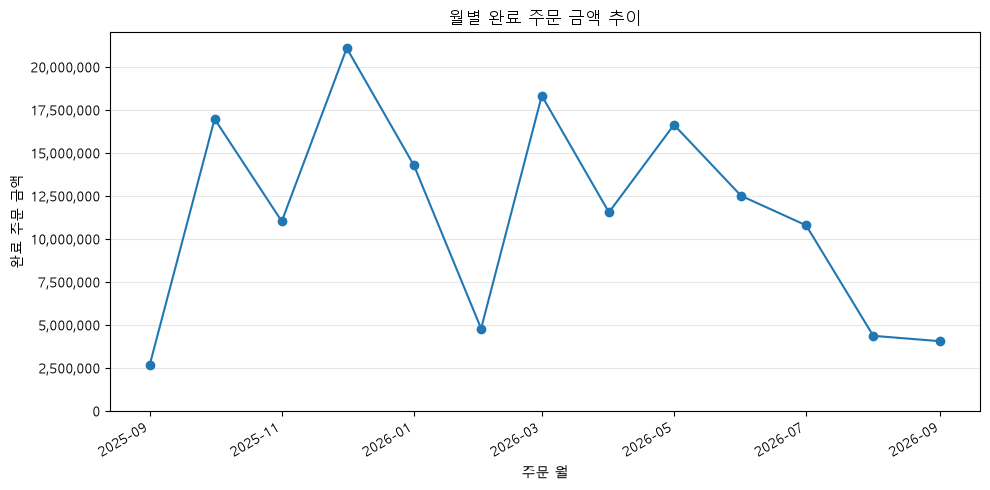

WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [8]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path
     

-## 2. 대표 그래프 1
![대표 그래프 1](images/01.png)

### 원본 집계값
- 2025-09부터 2026-09까지이며 제일 높은 달은 2025-12로 21,085,000(23건)이며, 제일 낮은 달은 2025-09 2,650,000(5건)로 집계

### 결과 관찰
- 2025-12랑 2026-03이 증가폭이 높고, 2025-09과 끝2026-09이 제일 낮음. 1,000만~1,600만 사이에서 변동발생

### 나의 해석과 판단
- 낮은 달은 대체로 주문 건수가 낮아 금액이 낮은 것으로 판단되며 날짜에 따라 변동폭이 바뀌는것은 아직 인과관계가 없어보인다

### 업무·분석적 의미
- 이 선그래프로는 추세를 판단하기 어려우며 "특정 달에 몰린 주문정도만 확인 가능하다

### 한계와 추가 확인 사항
- 양 끝 달이 완전한 한 달인지 확인하지 못함

In [9]:
from src.visualization import plot_product_price_hist

products["price"].describe()
     

count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
Name: price, dtype: float64

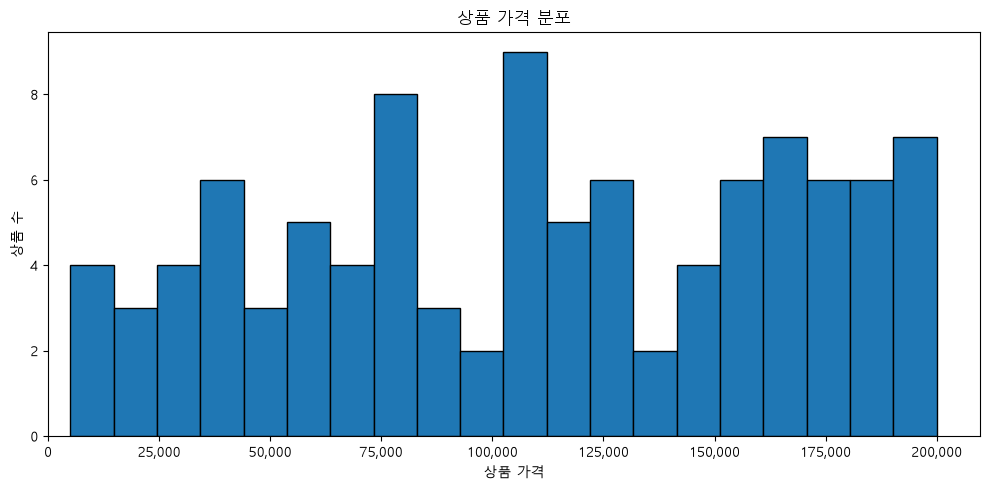

WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [10]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

## 3. 대표 그래프 2
![대표 그래프 2](images/02.png)

### 원본 집계값
- 총 상품은 100개이며 5,000~200,000원으로 분포. 중앙값 112,000와 평균이 110,040으로 거의 같음

### 결과 관찰
- 특정 한 구간에 확 몰렸다기보다 전체적으로 퍼져 있으며, 오히려 15~20만원 구간이 제일 많음

### 나의 해석과 판단
- 가격대가 고르게 분포되어 있으나 중간~고가 상품이 조금 더 많음. 다만 이건 어디까지나 상품가격 분포이며 많이 팔리는 분포는 아님

### 업무·분석적 의미
- 특정가격대가 판매가 잘되어 그 상품만 들여놓은 상황이 아니라는 것을 알 수 있음

### 한계와 추가 확인 사항
- 상품이 어느 가격에 몇 개 있는지일 뿐으로 그 가격대가 실제로 잘 팔리는지는 확인이 필요함


In [14]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(100)

,price,completed_quantity,completed_amount
39,163000,35,5705000
11,175000,25,4375000
8,193000,20,3860000
70,189000,20,3780000
69,161000,23,3703000
...,...,...,...
95,10000,13,130000
92,20000,6,120000
33,59000,2,118000
5,5000,18,90000


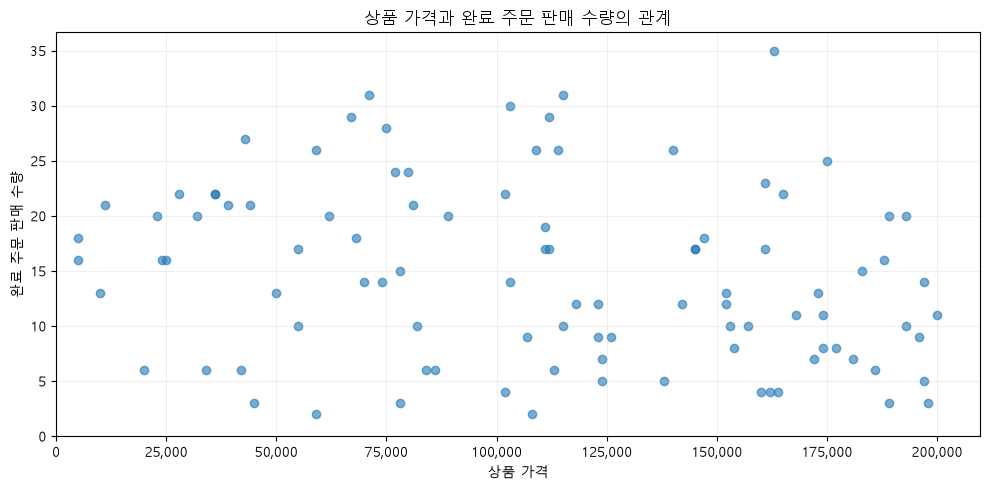

WindowsPath('c:/dev/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [12]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path
     

## 4. 대표 그래프 3
![대표 그래프 3](images/03.png)

### 원본 집계값
- 완료 주문 98개를 산점도 그래프로 표현 주문건수는 2~35건으로 분포

### 결과 관찰
- 분포가 넓게 퍼져 있어서 뚜렷한 직선 관계를 관찰하기 어려움. 제일 많이 팔린 상품들(30개 이상)은 7~16만원이며, 20만원 근처 품목은 대체로 적게 팔림

### 나의 해석과 판단
- 고가 품목이 덜팔리는 경향이 약간 있으나 이 그래프만으로 가격-수량 간 관계를 설명하긴 어려움

### 업무·분석적 의미
- 가격-수량간 영향을 미치는 요소가 카테고리나 할인 등 다른 요인이 더 크게 작용했을 수 있음

### 한계와 추가 확인 사항
- 완료 주문만 그래프로 확인한 자료로 취소·환불까지 넣으면 달라질 수 있음

## 5. 그래프 정확성 점검
- [X] 그래프 값과 집계표 값 일치
- [X] 축 이름 확인
- [X] 단위 확인
- [X] 범례 확인
- [X] 날짜 정렬 확인
- [X] 과장될 수 있는 축 범위 확인
- [X] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
- 히스토그램은 상품 "가격표" 분포지 많이 팔리는 가격대가 아니므로. 축 이름과 제목을 분명히 해야 "잘 팔리는 가격"에 대한 오해를 막을 수 있음
- 산점도의 약한 경향만 보고 상품-가격 간의 관계를 판단해선 안되며 추가적인 그래프와 수치를 보고 판단해야 함

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
- 산점도. 가격만 보는 것보다 가격과 완료 판매 수량을 같이 놓고 보기 떄문에 가격-수량 간의 관계를 확인할 수 있기 때문

### 그래프가 보여 준 사실
- 히스토그램을 보면 가격분포가 고르게 되어 있고 중고가 구간이 약간 집중된 것을 확인 할 수 있음. 다만 고가로 갈 수록 판매량이 적어지는 약한 경향이 있음

### 그래프만으로 말할 수 없는 것
- 중저가가 많이 팔린 게 가격 때문인지, 할인, 카테고리 등 같은 다른 이유 때문인지 이 그래프로는 알 수 없음

### 다음 분석에서 확인할 질문
- 카테고리별로 나눠도 똑같이 고가로 갈 수록 판매량이 적어지는 경향이 보이는지 확인 필요
